In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Dense,Dropout,Flatten
from tensorflow.keras.models import Sequential


In [ ]:
(x_train,y_train),(x_test,y_test) = mnist.load_data()

x_train = x_train.astype("float32")/255.0
x_test = x_test.astype("float32")/255.0

x_train = np.expand_dims(x_train,axis=-1)
x_test = np.expand_dims(x_test,axis=-1)

In [ ]:
model = Sequential([
    Conv2D(32,kernel_size=(3,3),activation="relu",input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Conv2D(64,kernel_size=(3,3),activation="relu"),
    MaxPooling2D((2,2)),
    Conv2D(128,kernel_size=(3,3),activation="relu"),
    Flatten(),
    Dense(128,activation="relu"),
    Dropout(0.5),
    Dense(10,activation="softmax")

])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
model.fit(
    x_train,y_train,epochs=5,batch_size=128,validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 105ms/step - accuracy: 0.9027 - loss: 0.3133 - val_accuracy: 0.9843 - val_loss: 0.0541
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 104ms/step - accuracy: 0.9776 - loss: 0.0785 - val_accuracy: 0.9895 - val_loss: 0.0390
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 107ms/step - accuracy: 0.9841 - loss: 0.0547 - val_accuracy: 0.9892 - val_loss: 0.0334
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.9871 - loss: 0.0436 - val_accuracy: 0.9898 - val_loss: 0.0358
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.9893 - loss: 0.0364 - val_accuracy: 0.9908 - val_loss: 0.0358


In [ ]:
test_loss,test_accuracy = model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9911 - loss: 0.0267


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


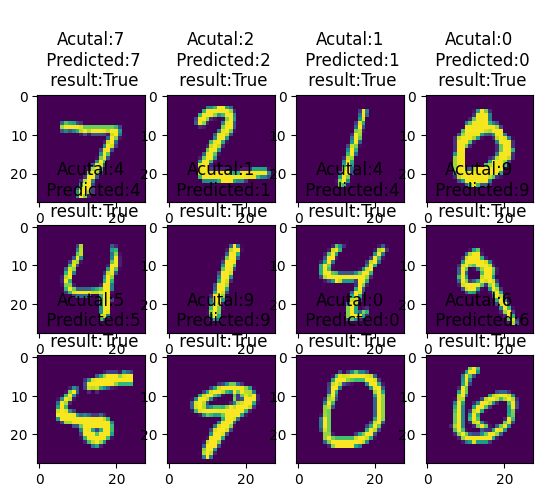

In [ ]:
prediction = model.predict(x_test)
predicted_digits = np.argmax(prediction,axis=1)
actual_digits=y_test

for i in range(12):
  plt.subplot(3,4,i+1)
  predicted = predicted_digits[i]
  actual = actual_digits[i]
  if actual==predicted:
    result="True"
  else:
    result="False"

  plt.imshow(x_test[i][:,:,0],label="Images")
  plt.title(
      f"\nAcutal:{actual}\n Predicted:{predicted}\n result:{result}"
  )